In [6]:
# ==========================================
# 1. SZEGMENT: Könyvtárak és hardver beállítása
# ==========================================

import torch
from diffusers import DiffusionPipeline
from transformers import BlipProcessor, BlipForConditionalGeneration,CLIPProcessor, CLIPModel
import matplotlib.pyplot as plt



device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
size = 512 if device == "cuda" else 256

CLIP_MIN = 0.15
CLIP_MAX = 0.35

# ==========================================
# 2. SZEGMENT: Modellek egyszeri betöltése
# ==========================================
pipe = DiffusionPipeline.from_pretrained(
    "stabilityai/sd-turbo",
    torch_dtype=dtype,
    variant="fp16" if device == "cuda" else None
).to(device)

processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
model = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-base",
    torch_dtype=dtype
).to(device)

#CLIP (Pontozás)
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

def make_image(text):
    return pipe(text, num_inference_steps=1, guidance_scale=0.0, height=size, width=size).images[0]


def describe_image(image):
    inputs = processor(image, return_tensors="pt").to(device, dtype)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=20)
    return processor.decode(out[0], skip_special_tokens=True)


def score(image, text):
    inputs = clip_proc(text=[text], images=image, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        out = clip(**inputs)
    raw = torch.cosine_similarity(out.image_embeds, out.text_embeds).item()
    ten = (raw - CLIP_MIN) / (CLIP_MAX - CLIP_MIN) * 10
    return max(0, min(10, ten))


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Kezdő szöveg: gun
Körök száma: 3
start: gun


  0%|          | 0/1 [00:00<?, ?it/s]

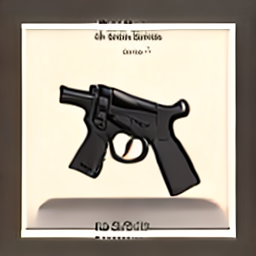

1. leírás: a black gun with a white background | Pontszám: 6.3/10


  0%|          | 0/1 [00:00<?, ?it/s]

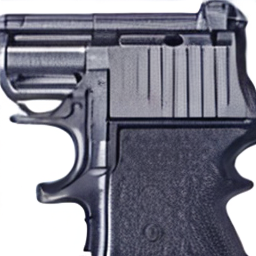

2. leírás: a handgun with a black trigger and a white background | Pontszám: 6.0/10


  0%|          | 0/1 [00:00<?, ?it/s]

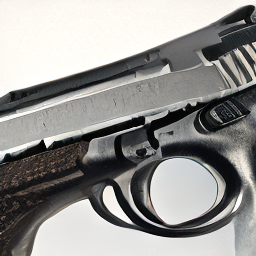

3. leírás: a gun with a black handle | Pontszám: 6.0/10




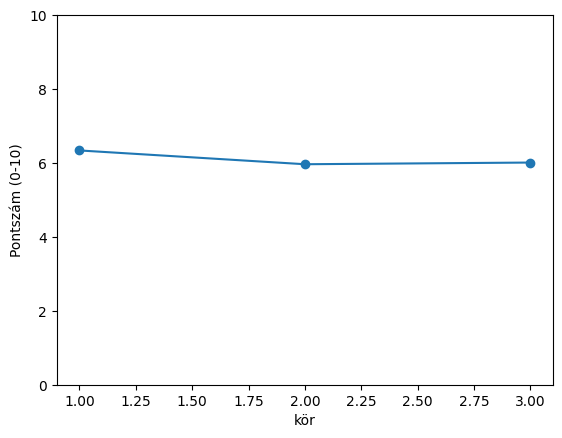

In [15]:
while True:
  Kezdo_szoveg=input("Kezdő szöveg: ")
  if type(Kezdo_szoveg) is str:
    break
  else:
    continue
while True:
  Korok = int(input("Körök száma: "))
  if type(Korok) is int:
    break
  else:
    print(type(Korok))
    continue

text = Kezdo_szoveg
scores = []
print("start:", text)

for i in range(1, Korok + 1):
    image = make_image(text)
    display(image)
    scores.append(score(image, Kezdo_szoveg))
    text = describe_image(image)
    print(f"{i}. leírás: {text} | Pontszám: {scores[-1]:.1f}/10")
plt.plot(range(1, Korok + 1), scores, marker="o")
plt.ylim(0, 10)
plt.xlabel("kör")
plt.ylabel("Pontszám (0-10)")
print()
print()
plt.show()